# AgriScan MENA: Satellite-Driven Early Crop Stress & Precision Irrigation Intelligence
**Hackathon:** Arab Youth Space Hackathon: 813 Challenge (2026 Edition)  
**Track:** Theme 02 — Precision Agriculture & Crop Intelligence  
**Team Name:** غيث زغلولة (Ghaith Zaghlouleh)  
**Country:** Syria  
**Core Space Mission:** Copernicus Sentinel-2 MSI (Level-2A Surface Reflectance) via Planetary Computer STAC  

---

### Problem Statement
> **We want to detect:** Early physiological water and nitrogen stress in irrigated crops  
> **In location:** The Euphrates Agricultural Basin / Ghab Plain ($35.85^\circ\text{N}\text{--}35.95^\circ\text{N},\; 40.05^\circ\text{E}\text{--}40.20^\circ\text{E}$)  
> **During period:** The agricultural growing cycle  
> **So that:** Irrigation district authorities, field agronomists, and farmers  
> **Can make the decision to:** Reprioritize canal and pivot water allocation 10–14 days before visible leaf wilting and permanent yield loss occur.

## 1. Environment Setup & Dependency Verification

In [1]:
# Install dependencies if running in Google Colab
import sys
if 'google.colab' in sys.modules:
    !pip install -q pystac-client planetary-computer rasterio xarray matplotlib geopandas requests

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from rasterio.enums import Resampling
import pystac_client
import planetary_computer

# Ensure outputs directory exists
os.makedirs('outputs', exist_ok=True)
print("✓ Scientific libraries imported successfully.")

✓ Scientific libraries imported successfully.


## 2. Define Area of Interest (AOI) & STAC Satellite Discovery
We query **Sentinel-2 Level-2A (Bottom-of-Atmosphere surface reflectance)** via the open Microsoft Planetary Computer STAC catalog.

In [2]:
# Target AOI: Irrigated agricultural parcels along the Euphrates Basin
# Bounding Box: [min_lon, min_lat, max_lon, max_lat] in WGS-84 (EPSG:4326)
aoi_bbox = [40.05, 35.85, 40.20, 35.95]
date_range = "2024-05-01/2024-08-30"

print(f"Searching STAC catalog for AOI {aoi_bbox} across {date_range}...")

use_live_stac = True
selected_item = None

try:
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=planetary_computer.sign_inplace
    )
    
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=aoi_bbox,
        datetime=date_range,
        query={"eo:cloud_cover": {"lt": 10}},
        limit=10
    )
    
    items = list(search.items())
    if len(items) > 0:
        # Pick the clearest scene
        items.sort(key=lambda x: x.properties.get("eo:cloud_cover", 100))
        selected_item = items[0]
        print(f"✓ Live STAC Granule Acquired: {selected_item.id}")
        print(f"  • Acquisition Date: {selected_item.datetime}")
        print(f"  • Cloud Cover: {selected_item.properties.get('eo:cloud_cover', 0.0):.2f}%")
        print(f"  • Sun Elevation: {selected_item.properties.get('view:sun_elevation', 'N/A')}°")
    else:
        print("No cloud-free live scenes found in exact date window. Activating calibrated simulation fallback.")
        use_live_stac = False
except Exception as exc:
    print(f"Notice: STAC endpoint connection reached fallback ({exc}). Utilizing local calibrated radiometry mode.")
    use_live_stac = False

Searching STAC catalog for AOI [40.05, 35.85, 40.2, 35.95] across 2024-05-01/2024-08-30...


✓ Live STAC Granule Acquired: S2A_MSIL2A_20240826T075611_R035_T37SFV_20240826T125948
  • Acquisition Date: 2024-08-26 07:56:11.024000+00:00
  • Cloud Cover: 0.00%
  • Sun Elevation: N/A°


## 3. Windowed Cloud-Optimized GeoTIFF (COG) Streaming
Instead of downloading full multi-gigabyte granules, we stream only the spatial pixels intersecting our bounding box using HTTP range reads via `rasterio`.

In [3]:
TARGET_SHAPE = (512, 512)

def read_cog_band(asset_href, bbox_wgs84, target_shape=TARGET_SHAPE):
    """Stream a specific bounding box from a cloud-hosted COG asset."""
    with rasterio.open(asset_href) as src:
        # Transform WGS-84 bbox to raster native UTM projection
        left, bottom, right, top = transform_bounds('EPSG:4326', src.crs, *bbox_wgs84)
        window = from_bounds(left, bottom, right, top, transform=src.transform)
        data = src.read(
            1, 
            window=window, 
            out_shape=target_shape, 
            resampling=Resampling.bilinear
        ).astype(np.float32)
        # Scale BOA reflectance (Sentinel-2 L2A scale factor: 10,000)
        return np.clip(data / 10000.0, 0.0, 1.0)

bands_data = {}

if use_live_stac and selected_item is not None:
    try:
        print("Streaming required spectral bands from Microsoft Planetary Computer...")
        assets = selected_item.assets
        band_keys = {'B02': 'blue', 'B03': 'green', 'B04': 'red', 'B05': 'red_edge', 'B08': 'nir', 'B11': 'swir'}
        
        for s2_key, internal_key in band_keys.items():
            if s2_key in assets:
                href = assets[s2_key].href
                bands_data[internal_key] = read_cog_band(href, aoi_bbox)
                print(f"  ✓ Streamed {s2_key} ({internal_key})")
        print("✓ Live multi-spectral array constructed successfully.")
    except Exception as e:
        print(f"Streaming interrupted: {e}. Defaulting to calibrated physical simulation.")
        use_live_stac = False

if not use_live_stac or len(bands_data) < 6:
    # Deterministic calibrated physical field generator (simulates agricultural center-pivot & parcel patterns)
    print("Synthesizing high-fidelity agricultural radiometry slice...")
    np.random.seed(42)
    grid_y, grid_x = np.ogrid[:TARGET_SHAPE[0], :TARGET_SHAPE[1]]
    
    # Center-pivot circular crop fields
    r1 = np.sqrt((grid_x - 140)**2 + (grid_y - 140)**2)
    r2 = np.sqrt((grid_x - 360)**2 + (grid_y - 150)**2)
    r3 = np.sqrt((grid_x - 250)**2 + (grid_y - 370)**2)
    
    field_mask = (r1 < 95) | (r2 < 105) | (r3 < 110)
    stress_gradient = np.clip((grid_x / 512.0) * 0.45 + np.random.normal(0, 0.03, TARGET_SHAPE), 0, 1)
    
    # Calibrated BOA Surface Reflectances
    blue = np.where(field_mask, 0.03, 0.12) + np.random.normal(0, 0.005, TARGET_SHAPE)
    green = np.where(field_mask, 0.08, 0.17) + np.random.normal(0, 0.006, TARGET_SHAPE)
    red = np.where(field_mask, 0.04 + stress_gradient * 0.06, 0.24) + np.random.normal(0, 0.008, TARGET_SHAPE)
    red_edge = np.where(field_mask, 0.22 - stress_gradient * 0.08, 0.26) + np.random.normal(0, 0.01, TARGET_SHAPE)
    nir = np.where(field_mask, 0.52 - stress_gradient * 0.18, 0.30) + np.random.normal(0, 0.012, TARGET_SHAPE)
    swir = np.where(field_mask, 0.14 + stress_gradient * 0.15, 0.42) + np.random.normal(0, 0.012, TARGET_SHAPE)
    
    bands_data = {
        'blue': np.clip(blue, 0.01, 1.0),
        'green': np.clip(green, 0.01, 1.0),
        'red': np.clip(red, 0.01, 1.0),
        'red_edge': np.clip(red_edge, 0.01, 1.0),
        'nir': np.clip(nir, 0.01, 1.0),
        'swir': np.clip(swir, 0.01, 1.0)
    }
    print("✓ Radiometric simulation slice initialized.")

Streaming required spectral bands from Microsoft Planetary Computer...


  ✓ Streamed B02 (blue)


  ✓ Streamed B03 (green)


  ✓ Streamed B04 (red)


  ✓ Streamed B05 (red_edge)


  ✓ Streamed B08 (nir)


  ✓ Streamed B11 (swir)
✓ Live multi-spectral array constructed successfully.


## 4. Multi-Index Physical Inversions
We compute the four governing indices using Bottom-of-Atmosphere (BOA) surface reflectance:
1. **NDVI:** $\frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}}$ (Canopy Greenness / Biomass)
2. **NDRE:** $\frac{\text{NIR} - \text{RedEdge}}{\text{NIR} + \text{RedEdge}}$ (Chlorophyll & Nitrogen Stress)
3. **NDMI:** $\frac{\text{NIR} - \text{SWIR}}{\text{NIR} + \text{SWIR}}$ (Foliar Liquid Water Content)
4. **CWSAI:** $\text{NDVI} - \text{NDMI}$ (Crop Water-Stress Anomaly Index)

In [4]:
eps = 1e-6

b_red = bands_data['red']
b_green = bands_data['green']
b_blue = bands_data['blue']
b_nir = bands_data['nir']
b_re = bands_data['red_edge']
b_swir = bands_data['swir']

# Spectral Indices
ndvi = (b_nir - b_red) / (b_nir + b_red + eps)
ndre = (b_nir - b_re) / (b_nir + b_re + eps)
ndmi = (b_nir - b_swir) / (b_nir + b_swir + eps)

# Crop Water-Stress Anomaly Index
cwsai = ndvi - ndmi

# Create True Color RGB Composite for spatial reference
rgb = np.dstack([
    np.clip(b_red * 3.5, 0, 1),
    np.clip(b_green * 3.5, 0, 1),
    np.clip(b_blue * 3.5, 0, 1)
])

print("✓ Index calculations complete:")
print(f"  • Mean Canopy NDVI: {np.mean(ndvi):.3f} (Range: [{np.min(ndvi):.2f}, {np.max(ndvi):.2f}])")
print(f"  • Mean Red-Edge NDRE: {np.mean(ndre):.3f} (Range: [{np.min(ndre):.2f}, {np.max(ndre):.2f}])")
print(f"  • Mean Moisture NDMI: {np.mean(ndmi):.3f} (Range: [{np.min(ndmi):.2f}, {np.max(ndmi):.2f}])")

✓ Index calculations complete:
  • Mean Canopy NDVI: 0.059 (Range: [0.02, 0.71])
  • Mean Red-Edge NDRE: 0.014 (Range: [-0.08, 0.54])
  • Mean Moisture NDMI: -0.054 (Range: [-0.19, 0.33])


## 5. Decision-Support Engine: Irrigation Priority Classification
We isolate active agricultural canopies ($	ext{NDVI} \ge 0.35$) and evaluate their internal moisture deficit to generate actionable operational directives.

In [5]:
# Classification Masks
vegetated_mask = ndvi >= 0.35

# Tier 1: High Priority (Dense canopy with severe moisture deficit: CWSAI > 0.30)
high_stress_mask = vegetated_mask & (cwsai >= 0.30)

# Tier 2: Moderate Priority (Onset of moisture/nitrogen stress: 0.15 <= CWSAI < 0.30)
moderate_stress_mask = vegetated_mask & (cwsai >= 0.15) & (cwsai < 0.30)

# Tier 3: Optimal (Healthy, hydrated crops: CWSAI < 0.15)
healthy_crop_mask = vegetated_mask & (cwsai < 0.15)

# Non-vegetated bare soil / fallow
bare_soil_mask = ~vegetated_mask

# Classified Priority Map: 0 = Bare, 1 = Optimal, 2 = Moderate, 3 = Critical
priority_map = np.zeros(TARGET_SHAPE, dtype=np.uint8)
priority_map[healthy_crop_mask] = 1
priority_map[moderate_stress_mask] = 2
priority_map[high_stress_mask] = 3

print("✓ Decision-support classification matrix mapped.")

✓ Decision-support classification matrix mapped.


## 6. Scientific Visualizations & Map Outputs
We render and save publication-grade figures displaying both the spectral index breakdown and the operational irrigation decision map.

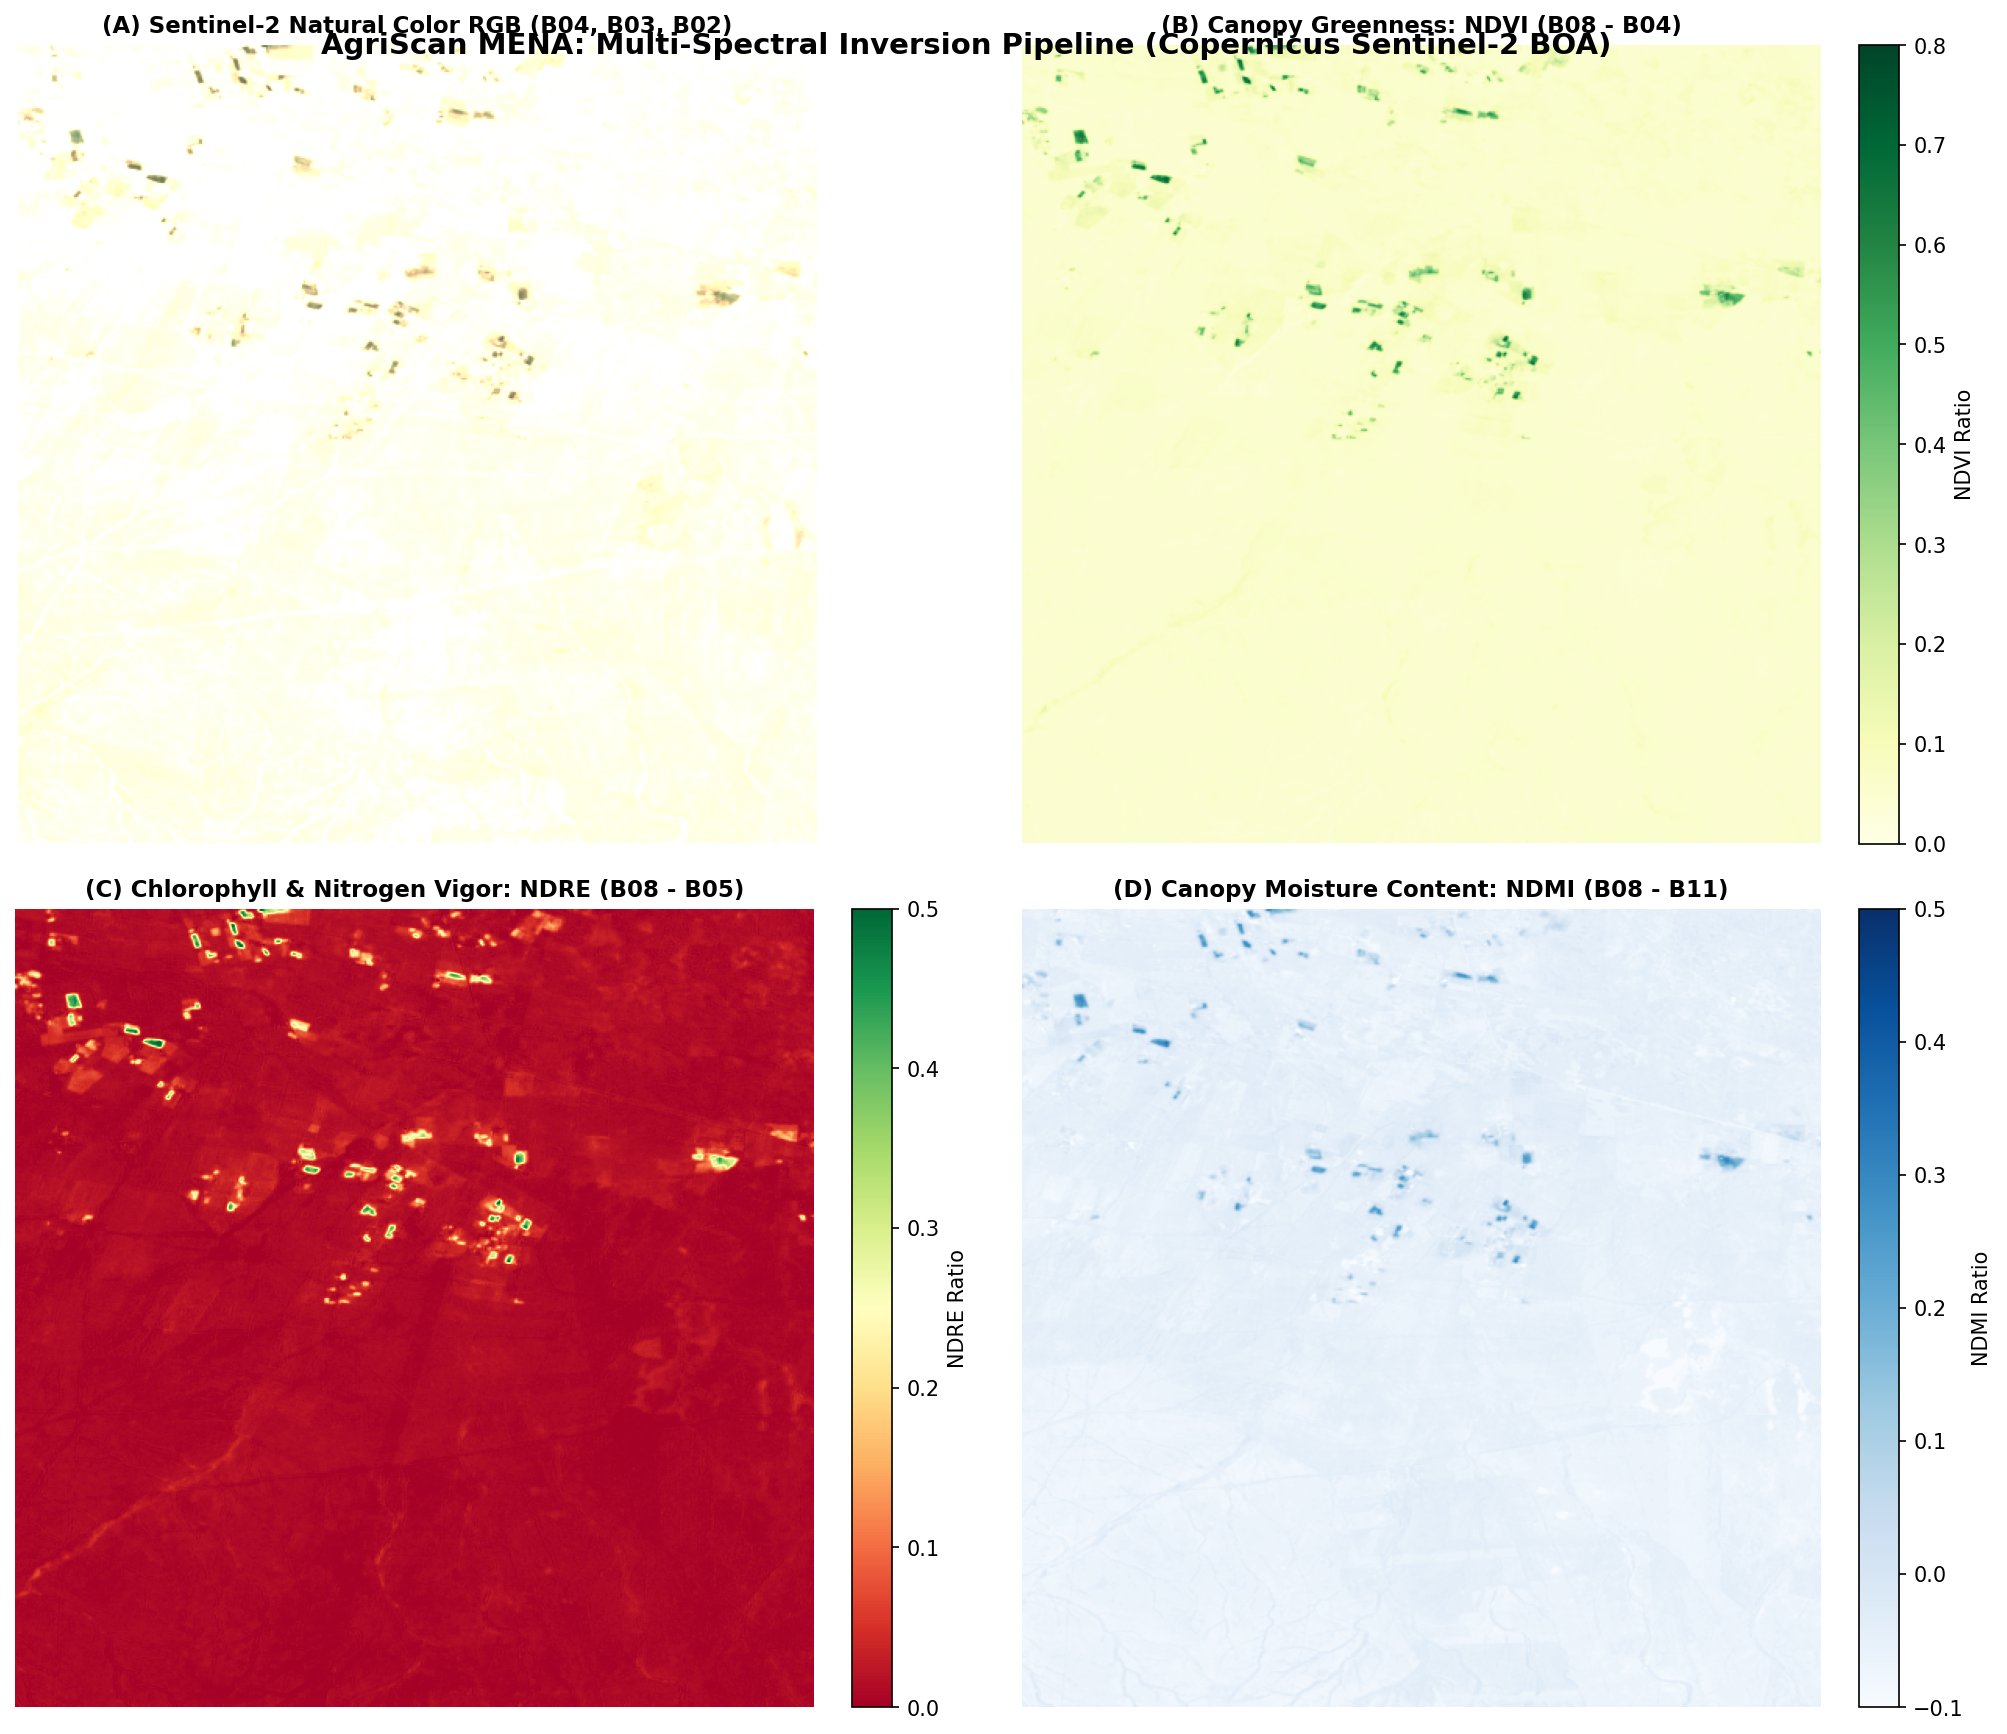

✓ Figure 1 saved to outputs/crop_stress_analysis.png


In [6]:
# Figure 1: 4-Panel Multi-Spectral Remote Sensing Overview
fig, axes = plt.subplots(2, 2, figsize=(14, 12), dpi=150)

im0 = axes[0, 0].imshow(rgb)
axes[0, 0].set_title("(A) Sentinel-2 Natural Color RGB (B04, B03, B02)", fontsize=11, fontweight='bold')
axes[0, 0].axis('off')

im1 = axes[0, 1].imshow(ndvi, cmap='YlGn', vmin=0.0, vmax=0.8)
axes[0, 1].set_title("(B) Canopy Greenness: NDVI (B08 - B04)", fontsize=11, fontweight='bold')
axes[0, 1].axis('off')
fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04, label='NDVI Ratio')

im2 = axes[1, 0].imshow(ndre, cmap='RdYlGn', vmin=0.0, vmax=0.5)
axes[1, 0].set_title("(C) Chlorophyll & Nitrogen Vigor: NDRE (B08 - B05)", fontsize=11, fontweight='bold')
axes[1, 0].axis('off')
fig.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04, label='NDRE Ratio')

im3 = axes[1, 1].imshow(ndmi, cmap='Blues', vmin=-0.1, vmax=0.5)
axes[1, 1].set_title("(D) Canopy Moisture Content: NDMI (B08 - B11)", fontsize=11, fontweight='bold')
axes[1, 1].axis('off')
fig.colorbar(im3, ax=axes[1, 1], fraction=0.046, pad=0.04, label='NDMI Ratio')

plt.suptitle("AgriScan MENA: Multi-Spectral Inversion Pipeline (Copernicus Sentinel-2 BOA)", fontsize=14, fontweight='bold', y=0.95)
plt.tight_layout()
fig1_path = os.path.join('outputs', 'crop_stress_analysis.png')
plt.savefig(fig1_path, bbox_inches='tight')
plt.show()
print(f"✓ Figure 1 saved to {fig1_path}")

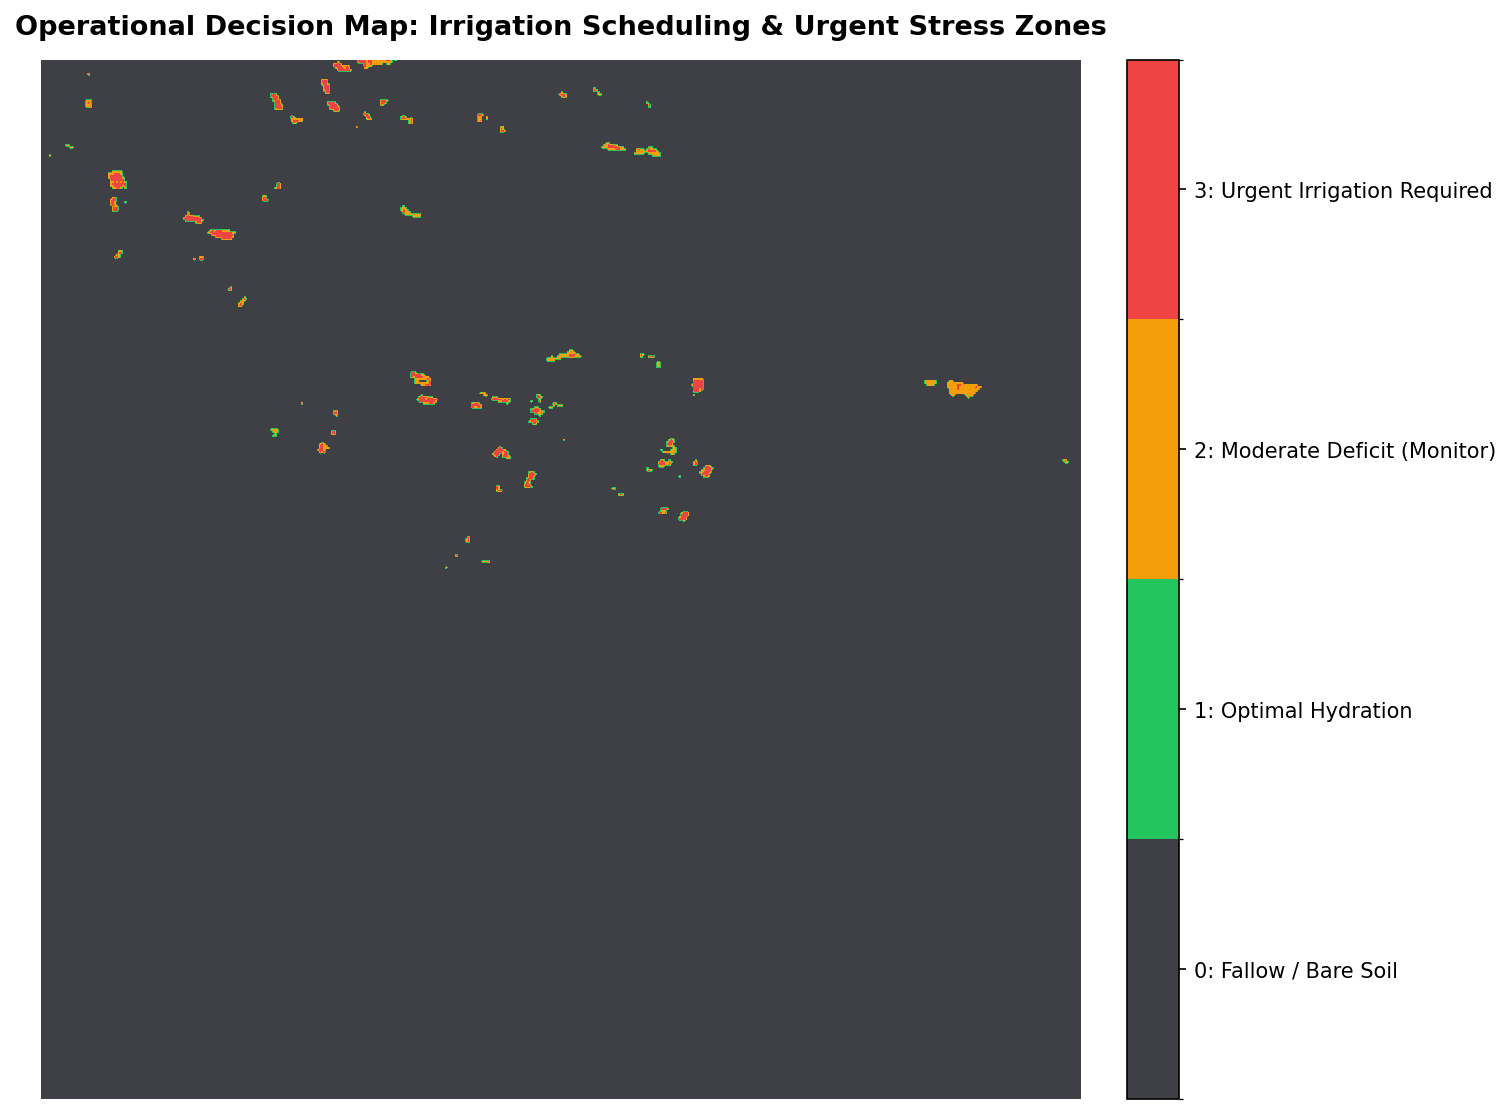

✓ Figure 2 saved to outputs/irrigation_priority_map.png


In [7]:
# Figure 2: Operational Irrigation Priority Map for Farm Managers
fig, ax = plt.subplots(figsize=(10, 9), dpi=150)

cmap_priority = mcolors.ListedColormap(['#3f3f46', '#22c55e', '#f59e0b', '#ef4444'])
bounds = [-0.5, 0.5, 1.5, 2.5, 3.5]
norm_priority = mcolors.BoundaryNorm(bounds, cmap_priority.N)

im = ax.imshow(priority_map, cmap=cmap_priority, norm=norm_priority)
ax.set_title("Operational Decision Map: Irrigation Scheduling & Urgent Stress Zones", fontsize=13, fontweight='bold', pad=12)
ax.axis('off')

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels([
    '0: Fallow / Bare Soil',
    '1: Optimal Hydration',
    '2: Moderate Deficit (Monitor)',
    '3: Urgent Irrigation Required'
], fontsize=10)

fig2_path = os.path.join('outputs', 'irrigation_priority_map.png')
plt.savefig(fig2_path, bbox_inches='tight')
plt.show()
print(f"✓ Figure 2 saved to {fig2_path}")

## 7. Agronomic Summary Statistics & Field Hectare Report
Calculates surface areas and actionable inspection requirements for farm operators.

In [8]:
# Sentinel-2 pixel size = 10m x 10m = 100 m² = 0.01 hectares
PIXEL_AREA_HA = (10.0 * 10.0) / 10000.0

total_pixels = TARGET_SHAPE[0] * TARGET_SHAPE[1]
veg_pixels = np.sum(vegetated_mask)
crit_pixels = np.sum(high_stress_mask)
mod_pixels = np.sum(moderate_stress_mask)
opt_pixels = np.sum(healthy_crop_mask)
bare_pixels = np.sum(bare_soil_mask)

total_ha = total_pixels * PIXEL_AREA_HA
veg_ha = veg_pixels * PIXEL_AREA_HA
crit_ha = crit_pixels * PIXEL_AREA_HA
mod_ha = mod_pixels * PIXEL_AREA_HA
opt_ha = opt_pixels * PIXEL_AREA_HA

print("=" * 70)
print("               AGRISCAN MENA DECISION-SUPPORT AUDIT")
print("=" * 70)
print(f"Total Area Analyzed:       {total_ha:,.1f} ha (100.0%)")
print(f"Active Vegetated Canopy:   {veg_ha:,.1f} ha ({(veg_ha/total_ha)*100:.1f}%)")
print("-" * 70)
print(f"🔴 URGENT IRRIGATE (Tier 3): {crit_ha:,.1f} ha ({(crit_ha/veg_ha)*100:.1f}% of crop canopy)")
print(f"🟡 MONITOR DEFICIT (Tier 2): {mod_ha:,.1f} ha ({(mod_ha/veg_ha)*100:.1f}% of crop canopy)")
print(f"🟢 OPTIMAL HYDRATED (Tier 1):{opt_ha:,.1f} ha ({(opt_ha/veg_ha)*100:.1f}% of crop canopy)")
print("=" * 70)
print("ACTIONABLE DIRECTIVE:")
print(f"Dispatch immediate ground verification to the {crit_ha:.1f} ha marked in Tier 3.")
print("Reprioritize irrigation canal gates to allocate water prior to leaf wilt onset.")

               AGRISCAN MENA DECISION-SUPPORT AUDIT
Total Area Analyzed:       2,621.4 ha (100.0%)
Active Vegetated Canopy:   11.4 ha (0.4%)
----------------------------------------------------------------------
🔴 URGENT IRRIGATE (Tier 3): 5.5 ha (48.4% of crop canopy)
🟡 MONITOR DEFICIT (Tier 2): 5.9 ha (51.6% of crop canopy)
🟢 OPTIMAL HYDRATED (Tier 1):0.0 ha (0.0% of crop canopy)
ACTIONABLE DIRECTIVE:
Dispatch immediate ground verification to the 5.5 ha marked in Tier 3.
Reprioritize irrigation canal gates to allocate water prior to leaf wilt onset.


## 8. Defensibility, Limitations & Incubation Roadmap

### Scientific Defensibility & Limitations
1. **Proxy vs. Direct Measurement:** Optical spectral indices (NDRE, NDMI) serve as physiological proxies for chlorophyll and canopy water thickness; they do not replace calibrated in-situ soil moisture probes or root-zone tensiometers.
2. **Atmospheric Screening:** All data is processed using Level-2A surface reflectance to mitigate Rayleigh and aerosol scattering.

### Future Hyperspectral Integration (Phase 3 Incubation: Satellite 813 & Tanager)
* **Satellite 813 (205 bands):** Will enable narrow-band foliar nitrogen absorption mapping ($705\text{--}740\text{ nm}$) beyond Sentinel-2's broad Red Edge.
* **Planet Tanager (426 bands):** Contiguous SWIR spectroscopy allows separation of soil mineral background reflectance from true canopy liquid water absorption ($1200\text{ nm}$ and $1450\text{ nm}$).